# MarketPulse LK – Advanced Statistical Analysis
## Advanced Statistics for Data Science
**Project Title**: Statistical Modelling of Volatility, Financial Risk and Market Regime Changes in Selected Colombo Stock Exchange Equities Using Time-Series and Machine Learning Techniques  
**Equities under Investigation**:
1. **John Keells Holdings PLC (JKH)** – Diversified Conglomerate / Market Bellwether
2. **Hayleys PLC (HAYL)** – Export, Logistics & Industrial Manufacturing Conglomerate
3. **Vallibel One PLC (VONE)** – Industrial Manufacturing & Financial Services Conglomerate

---

### Analytical Architecture & Research Scope (Part 05)
This notebook implements **Part 05: Advanced Statistical Analysis**. Building on the exploratory empirical baseline established in Part 04 (EDA), this module executes formal asymptotic and non-parametric hypothesis testing to establish the core time-series and distributional properties of Colombo Stock Exchange daily equity returns.

### Core Objectives:
1. **Stationarity & Integration Analysis**: Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests to ascertain the integration order $I(d)$ of price and return series.
2. **Autocorrelation & Serial Dependence**: Autocorrelation (ACF) and Partial Autocorrelation (PACF) up to lag 40 for levels, squared returns ($r_t^2$), and absolute returns ($|r_t|$).
3. **Portmanteau Autocorrelation Tests**: Ljung-Box $Q$-tests at multiple lag orders ($m = 10, 20$) testing for weak-form efficiency and linear/non-linear dependence.
4. **Normality Goodness-of-Fit Synthesis**: Consolidating empirical higher moments with Jarque-Bera tests from EDA.
5. **Conditional Heteroskedasticity (ARCH-LM)**: Engle's Lagrange Multiplier test to verify autoregressive conditional heteroskedasticity and establish statistical justification for GARCH modeling.
6. **Parameter Instability & Structural Breaks**: OLS-CUSUM fluctuation tests and Zivot-Andrews endogenous single-break unit root tests.
7. **Asymmetric Volatility Dynamics**: Engle-Ng sign and size bias tests evaluating leverage and asymmetric information shocks.
8. **Comparative Synthesis**: Cross-sectional econometric comparison across JKH, HAYL, and VONE.


In [2]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf, zivot_andrews
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, breaks_cusumolsresid
import arch
from arch import arch_model

# Visual aesthetics configuration for academic reporting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Output directory routing
figures_base = os.path.join('..', 'outputs', 'figures', 'advanced_statistics')
tables_base = os.path.join('..', 'outputs', 'tables')
processed_dir = os.path.join('..', 'data', 'processed')

os.makedirs(figures_base, exist_ok=True)
os.makedirs(tables_base, exist_ok=True)

# Color scheme matching project standard
palette = {'JKH': '#1f77b4', 'HAYL': '#ff7f0e', 'VONE': '#2ca02c'}

print(f"Environment Verification:")
print(f"- Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | NumPy: {np.__version__}")
print(f"- Statsmodels: {sm.__version__} | ARCH: {arch.__version__}")


ModuleNotFoundError: No module named 'scipy'

---
## STEP 01 – Dataset Loading and Verification

### 1.1 Purpose of the Analysis
Prior to conducting formal asymptotic hypothesis tests, this step verifies:
- Accessibility and schema conformance of cleaned datasets in `data/processed/`.
- Date range synchronization across 2014-01-02 to 2026-10-14.
- Availability and definition of price metrics (`Adjusted_Close`) and return series:
  - Percentage return: $R_t = \left(\frac{P_t}{P_{t-1}} - 1\right) \times 100$
  - Continuously compounded log return: $r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$
- Cross-referencing previously completed EDA tables in `outputs/tables/` to avoid redundant computation.


In [ ]:
equities = ['JKH', 'HAYL', 'VONE']
dfs = {}

for eq in equities:
    filepath = os.path.join(processed_dir, f"{eq}_cleaned.csv")
    df = pd.read_csv(filepath)
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values('Date').reset_index(drop=True)
    
    # Calculate exact percentage and log returns from Adjusted_Close
    df['Pct_Return'] = df['Adjusted_Close'].pct_change() * 100
    df['Log_Return_Calc'] = np.log(df['Adjusted_Close'] / df['Adjusted_Close'].shift(1))
    
    # Preserve row 0 values
    if pd.notnull(df.loc[0, 'Log_Return']):
        df.loc[0, 'Log_Return_Calc'] = df.loc[0, 'Log_Return']
    if pd.notnull(df.loc[0, 'Change_%']):
        df.loc[0, 'Pct_Return'] = df.loc[0, 'Change_%']
        
    dfs[eq] = df

# Generate Verification Summary Table
verif_rows = []
for eq in equities:
    df = dfs[eq]
    verif_rows.append({
        'Company': eq,
        'Observations (T)': len(df),
        'Start Date': df['Date'].min().strftime('%Y-%m-%d'),
        'End Date': df['Date'].max().strftime('%Y-%m-%d'),
        'Has Adjusted_Close': 'Adjusted_Close' in df.columns,
        'Has Pct_Return': 'Pct_Return' in df.columns,
        'Has Log_Return': 'Log_Return_Calc' in df.columns,
        'Pct_Return Nulls': df['Pct_Return'].isnull().sum(),
        'Log_Return Nulls': df['Log_Return_Calc'].isnull().sum(),
        'Monotonic Ascending': df['Date'].is_monotonic_increasing
    })

verif_table = pd.DataFrame(verif_rows)
display(verif_table)
print(verif_table.to_string(index=False))


,Company,Observations (T),Start Date,End Date,Has Adjusted_Close,Has Pct_Return,Has Log_Return,Pct_Return Nulls,Log_Return Nulls,Monotonic Ascending
0,JKH,2971,2014-01-02,2026-10-14,True,True,True,0,0,True
1,HAYL,2725,2014-01-02,2026-10-14,True,True,True,0,0,True
2,VONE,2910,2014-01-02,2026-10-14,True,True,True,0,0,True


Company  Observations (T) Start Date   End Date  Has Adjusted_Close  Has Pct_Return  Has Log_Return  Pct_Return Nulls  Log_Return Nulls  Monotonic Ascending
    JKH              2971 2014-01-02 2026-10-14                True            True            True                 0                 0                 True
   HAYL              2725 2014-01-02 2026-10-14                True            True            True                 0                 0                 True
   VONE              2910 2014-01-02 2026-10-14                True            True            True                 0                 0                 True


---
## STEP 02 – Stationarity Analysis (ADF & KPSS Tests)

### 2.1 Purpose of the Analysis
Stationarity is an indispensable precondition for linear and non-linear time-series modeling. Non-stationary variables generate spurious regression regressions, non-convergent parameter estimators, and invalid asymptotic distributions. We deploy a dual-testing methodology:
1. **Augmented Dickey-Fuller (ADF) Test**: Tests the null hypothesis of a unit root against the alternative of stationarity.
2. **Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test**: Tests the null hypothesis of stationarity against the alternative of a unit root.

### 2.2 Relevant Statistical & Econometric Theory
- **Augmented Dickey-Fuller (ADF) Regression**:
  $$\Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \sum_{i=1}^p \delta_i \Delta y_{t-i} + \varepsilon_t$$
  - Hypotheses:
    - $H_0: \gamma = 0$ (The series contains a unit root; non-stationary)
    - $H_1: \gamma < 0$ (The series contains no unit root; stationary)
  - Decision Rule (at $\alpha = 0.05$): Reject $H_0$ if $p < 0.05$ (or ADF statistic $<$ critical value).
- **KPSS Test**:
  Assumes the series decomposes into a deterministic trend, a random walk, and a stationary error:
  $$y_t = r_t + \beta t + \varepsilon_t, \quad r_t = r_{t-1} + u_t, \quad u_t \sim \text{i.i.d.}(0, \sigma_u^2)$$
  - Hypotheses:
    - $H_0: \sigma_u^2 = 0$ (The series is stationary around a constant/trend)
    - $H_1: \sigma_u^2 > 0$ (The series is non-stationary / unit root)
  - Decision Rule (at $\alpha = 0.05$): Reject $H_0$ if $p < 0.05$ (or KPSS statistic $>$ critical value).
- **Combined Stationarity Decision Matrix**:
  - *Case 1 (ADF rejects $H_0$, KPSS fails to reject $H_0$)*: Robust Stationarity ($I(0)$).
  - *Case 2 (ADF fails to reject $H_0$, KPSS rejects $H_0$)*: Robust Non-Stationarity ($I(1)$).
  - *Case 3 (ADF rejects $H_0$, KPSS rejects $H_0$)*: Stationary with Structural Breaks / Long Memory.
  - *Case 4 (ADF fails to reject $H_0$, KPSS fails to reject $H_0$)*: Inconclusive / Low Power.


In [ ]:
adf_rows = []
kpss_rows = []
stat_summary_rows = []

for eq in equities:
    df = dfs[eq]
    
    series_dict = [
        ('Adjusted_Close', 'Price Level (LKR)', df['Adjusted_Close'].dropna().values),
        ('Pct_Return', 'Daily Percentage Return (%)', df['Pct_Return'].dropna().values),
        ('Log_Return', 'Daily Log Return', df['Log_Return_Calc'].dropna().values)
    ]
    
    for col_key, var_name, data in series_dict:
        # ADF Test
        adf_res = adfuller(data, regression='c', autolag='AIC')
        adf_stat, adf_pval, used_lag, n_obs, crit_vals = adf_res[0], adf_res[1], adf_res[2], adf_res[3], adf_res[4]
        adf_decision = "Reject H0 (Stationary)" if adf_pval < 0.05 else "Fail to Reject H0 (Non-Stationary)"
        
        adf_rows.append({
            'Company': eq,
            'Variable': var_name,
            'Test': 'Augmented Dickey-Fuller (ADF)',
            'ADF_Statistic': adf_stat,
            'p_value': adf_pval,
            'Lags_Used': used_lag,
            'Observations': n_obs,
            'Critical_1%': crit_vals['1%'],
            'Critical_5%': crit_vals['5%'],
            'Critical_10%': crit_vals['10%'],
            'Decision_α=0.05': adf_decision
        })
        
        # KPSS Test
        kpss_res = kpss(data, regression='c', nlags='auto')
        kpss_stat, kpss_pval, kpss_lags, kpss_crit = kpss_res[0], kpss_res[1], kpss_res[2], kpss_res[3]
        kpss_decision = "Reject H0 (Non-Stationary)" if kpss_pval < 0.05 else "Fail to Reject H0 (Stationary)"
        
        kpss_rows.append({
            'Company': eq,
            'Variable': var_name,
            'Test': 'KPSS Test',
            'KPSS_Statistic': kpss_stat,
            'p_value': kpss_pval,
            'Lags_Used': kpss_lags,
            'Critical_1%': kpss_crit['1%'],
            'Critical_5%': kpss_crit['5%'],
            'Critical_10%': kpss_crit['10%'],
            'Decision_α=0.05': kpss_decision
        })
        
        # Joint Decision Matrix
        if adf_pval < 0.05 and kpss_pval >= 0.05:
            joint_decision = "Stationary (Strong Agreement: Both indicate I(0))"
        elif adf_pval >= 0.05 and kpss_pval < 0.05:
            joint_decision = "Non-Stationary / Unit Root (Strong Agreement: Both indicate I(1))"
        elif adf_pval < 0.05 and kpss_pval < 0.05:
            joint_decision = "Stationary with Structural Breaks / Long Memory (ADF rejects, KPSS rejects)"
        else:
            joint_decision = "Inconclusive / Weak Evidence (ADF fails, KPSS fails)"
            
        stat_summary_rows.append({
            'Company': eq,
            'Variable': var_name,
            'ADF_Stat': round(adf_stat, 4),
            'ADF_pvalue': f"{adf_pval:.4e}" if adf_pval < 0.0001 else f"{adf_pval:.4f}",
            'ADF_Conclusion': "Stationary" if adf_pval < 0.05 else "Non-Stationary",
            'KPSS_Stat': round(kpss_stat, 4),
            'KPSS_pvalue': f"{kpss_pval:.4e}" if kpss_pval < 0.0001 else f"{kpss_pval:.4f}",
            'KPSS_Conclusion': "Non-Stationary" if kpss_pval < 0.05 else "Stationary",
            'Combined_Stationarity_Decision': joint_decision
        })

df_adf = pd.DataFrame(adf_rows)
df_kpss = pd.DataFrame(kpss_rows)
df_stat_sum = pd.DataFrame(stat_summary_rows)

df_adf.to_csv(os.path.join(tables_base, 'adf_test_results.csv'), index=False)
df_kpss.to_csv(os.path.join(tables_base, 'kpss_test_results.csv'), index=False)
df_stat_sum.to_csv(os.path.join(tables_base, 'stationarity_summary.csv'), index=False)
print("Saved adf_test_results.csv, kpss_test_results.csv, and stationarity_summary.csv")

display(df_stat_sum)
print(df_stat_sum.to_string(index=False))


/var/folders/kr/hzc2dh_s2dq0sks6j51blgvm0000gn/T/ipykernel_12881/1593188562.py:35: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(data, regression='c', nlags='auto')
/var/folders/kr/hzc2dh_s2dq0sks6j51blgvm0000gn/T/ipykernel_12881/1593188562.py:35: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(data, regression='c', nlags='auto')
/var/folders/kr/hzc2dh_s2dq0sks6j51blgvm0000gn/T/ipykernel_12881/1593188562.py:35: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(data, regression='c', nlags='auto')
/var/folders/kr/hzc2dh_s2dq0sks6j51blgvm0000gn/T/ipykernel_12881/1593188562.py:35: Interpol

Saved adf_test_results.csv, kpss_test_results.csv, and stationarity_summary.csv


/var/folders/kr/hzc2dh_s2dq0sks6j51blgvm0000gn/T/ipykernel_12881/1593188562.py:35: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(data, regression='c', nlags='auto')
/var/folders/kr/hzc2dh_s2dq0sks6j51blgvm0000gn/T/ipykernel_12881/1593188562.py:35: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(data, regression='c', nlags='auto')
/var/folders/kr/hzc2dh_s2dq0sks6j51blgvm0000gn/T/ipykernel_12881/1593188562.py:35: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_res = kpss(data, regression='c', nlags='auto')
/var/folders/kr/hzc2dh_s2dq0sks6j51blgvm0000gn/T/ipykernel_12881/1593188562.py:35: Interpol

,Company,Variable,ADF_Stat,ADF_pvalue,ADF_Conclusion,KPSS_Stat,KPSS_pvalue,KPSS_Conclusion,Combined_Stationarity_Decision
0,JKH,Price Level (LKR),-2.4581,0.1260,Non-Stationary,1.6842,0.0100,Non-Stationary,Non-Stationary / Unit Root (Strong Agreement: ...
1,JKH,Daily Percentage Return (%),-23.9419,0.0000e+00,Stationary,0.1034,0.1000,Stationary,Stationary (Strong Agreement: Both indicate I(0))
2,JKH,Daily Log Return,-23.7379,0.0000e+00,Stationary,0.0873,0.1000,Stationary,Stationary (Strong Agreement: Both indicate I(0))
3,HAYL,Price Level (LKR),0.4021,0.9816,Non-Stationary,6.1633,0.0100,Non-Stationary,Non-Stationary / Unit Root (Strong Agreement: ...
4,HAYL,Daily Percentage Return (%),-11.0133,6.2482e-20,Stationary,0.2853,0.1000,Stationary,Stationary (Strong Agreement: Both indicate I(0))
5,HAYL,Daily Log Return,-10.9929,6.9881e-20,Stationary,0.2332,0.1000,Stationary,Stationary (Strong Agreement: Both indicate I(0))
6,VONE,Price Level (LKR),-0.9926,0.7560,Non-Stationary,6.1082,0.0100,Non-Stationary,Non-Stationary / Unit Root (Strong Agreement: ...
7,VONE,Daily Percentage Return (%),-11.4145,7.1186e-21,Stationary,0.1088,0.1000,Stationary,Stationary (Strong Agreement: Both indicate I(0))
8,VONE,Daily Log Return,-11.4361,6.3427e-21,Stationary,0.0675,0.1000,Stationary,Stationary (Strong Agreement: Both indicate I(0))


Company                    Variable  ADF_Stat ADF_pvalue ADF_Conclusion  KPSS_Stat KPSS_pvalue KPSS_Conclusion                                    Combined_Stationarity_Decision
    JKH           Price Level (LKR)   -2.4581     0.1260 Non-Stationary     1.6842      0.0100  Non-Stationary Non-Stationary / Unit Root (Strong Agreement: Both indicate I(1))
    JKH Daily Percentage Return (%)  -23.9419 0.0000e+00     Stationary     0.1034      0.1000      Stationary                 Stationary (Strong Agreement: Both indicate I(0))
    JKH            Daily Log Return  -23.7379 0.0000e+00     Stationary     0.0873      0.1000      Stationary                 Stationary (Strong Agreement: Both indicate I(0))
   HAYL           Price Level (LKR)    0.4021     0.9816 Non-Stationary     6.1633      0.0100  Non-Stationary Non-Stationary / Unit Root (Strong Agreement: Both indicate I(1))
   HAYL Daily Percentage Return (%)  -11.0133 6.2482e-20     Stationary     0.2853      0.1000      Stationary     

---
## STEP 03 – Autocorrelation Analysis (ACF & PACF)

### 3.1 Purpose of the Analysis
This section analyzes linear and non-linear temporal dependence across returns:
1. **Autocorrelation Function (ACF)**: Quantifies total linear correlation between $r_t$ and its lagged values $r_{t-k}$.
2. **Partial Autocorrelation Function (PACF)**: Measures direct correlation between $r_t$ and $r_{t-k}$ after partialling out intermediate lags $1, \dots, k-1$.
3. **Squared Returns ($r_t^2$) and Absolute Returns ($|r_t|$)**: Evaluates higher-moment non-linear dependence and persistent volatility memory (the Taylor Effect).

### 3.2 Relevant Statistical Theory
- Under the Efficient Market Hypothesis (EMH) in its weak form, asset returns should behave as a martingale difference sequence: $\mathbb{E}[r_t | \mathcal{F}_{t-1}] = 0$, implying $\rho_k = 0$ for all $k \ge 1$.
- However, financial returns frequently exhibit the *stylized fact of volatility clustering*: while returns $r_t$ show little or no linear autocorrelation, squared returns $r_t^2$ and absolute returns $|r_t|$ exhibit strong, slowly decaying positive autocorrelation extending over dozens of lags.
- *Confidence Bands*: For sample size $T$, the $95\%$ Bartlett asymptotic confidence interval under the null of white noise is $\pm \frac{1.96}{\sqrt{T}}$.


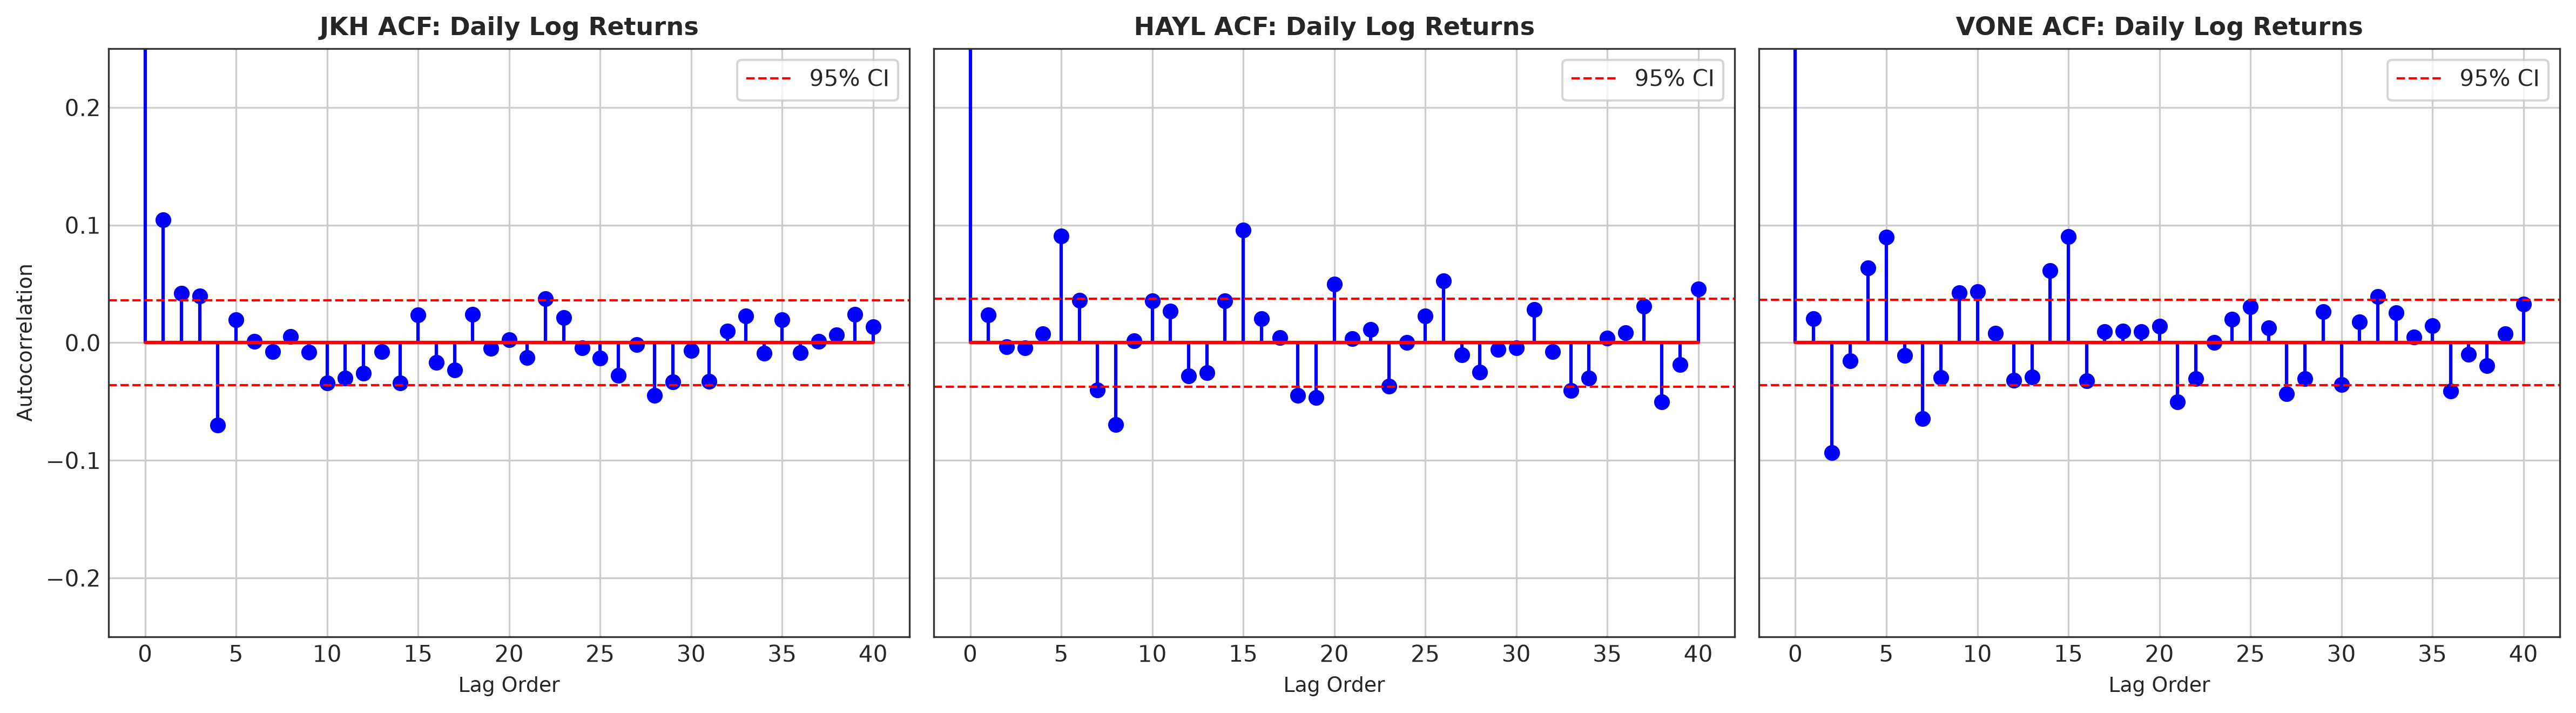

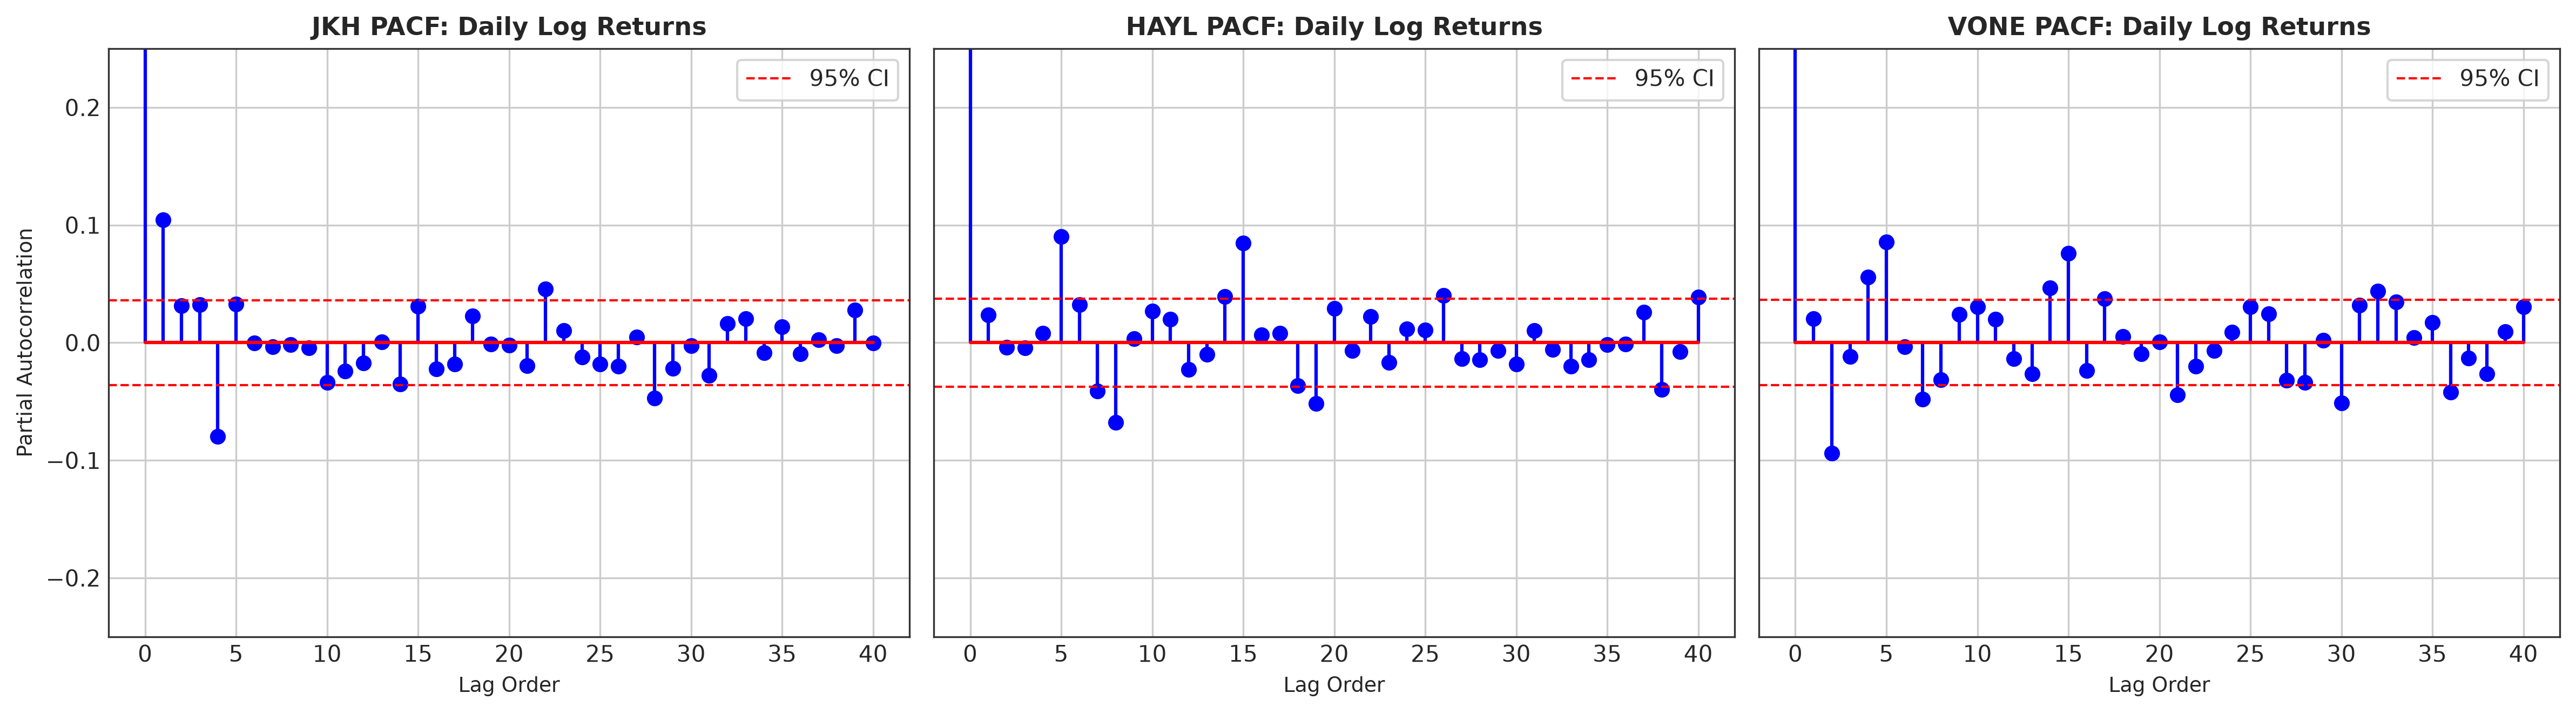

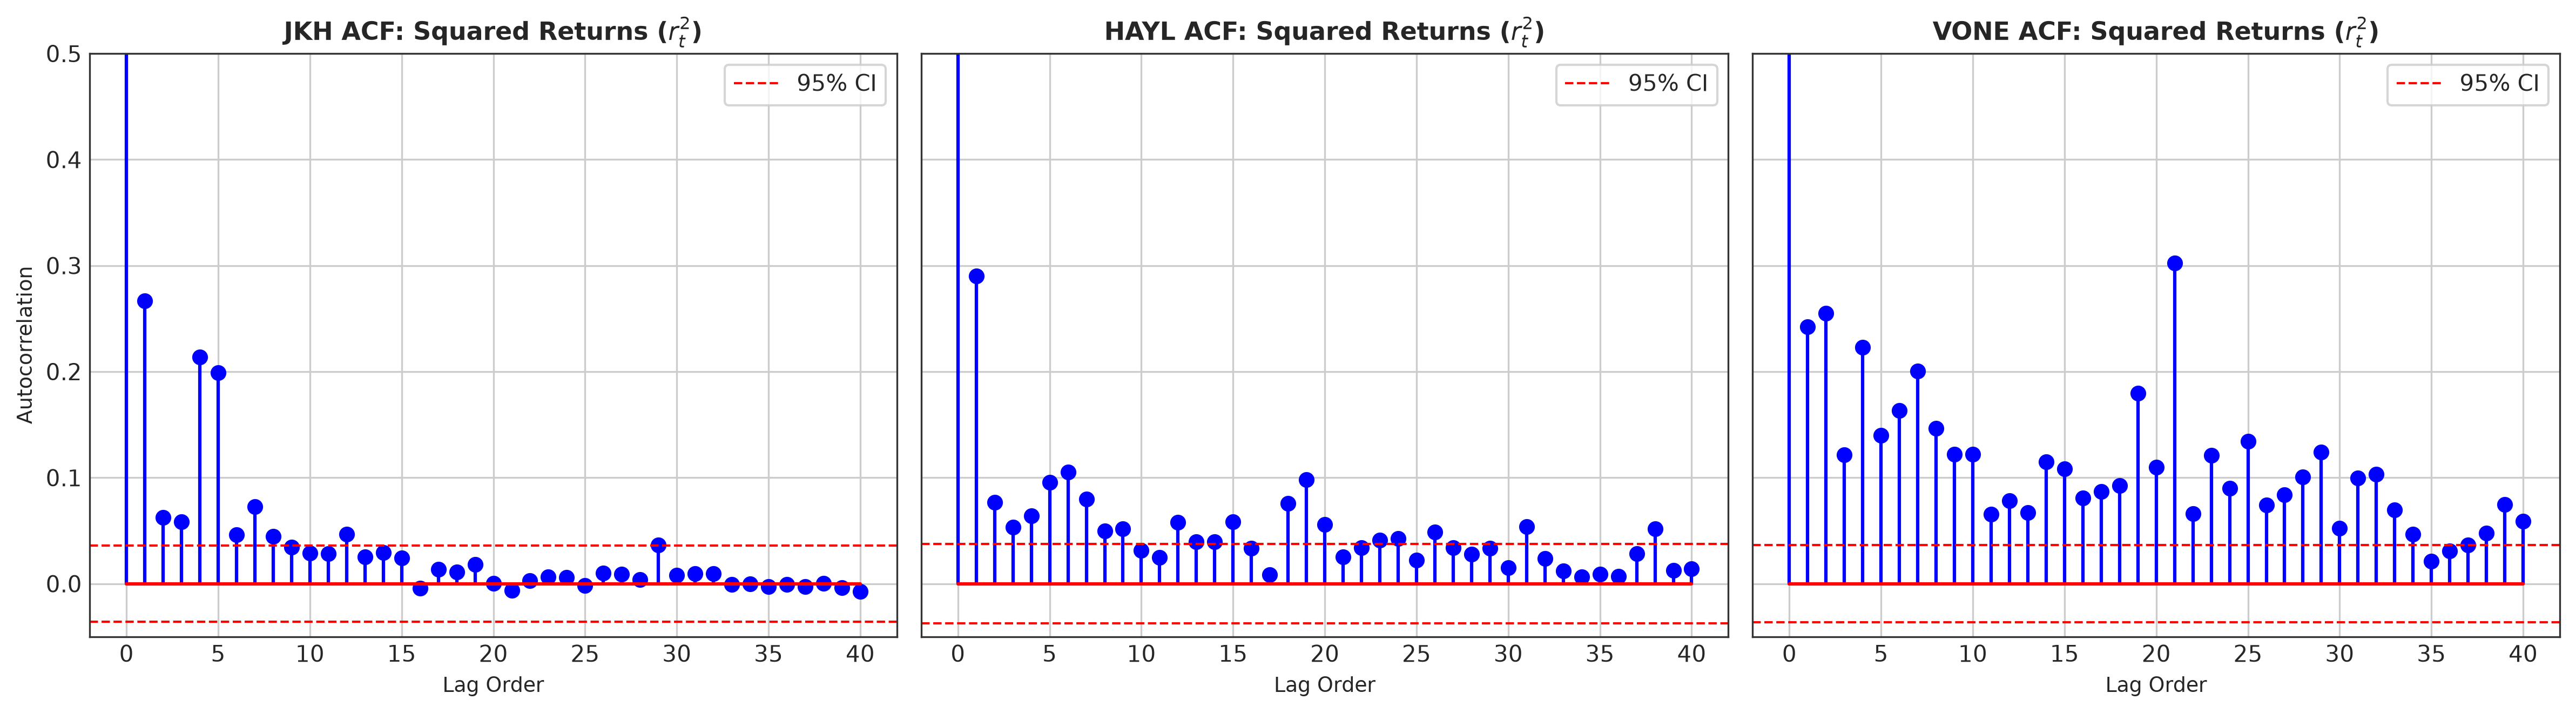

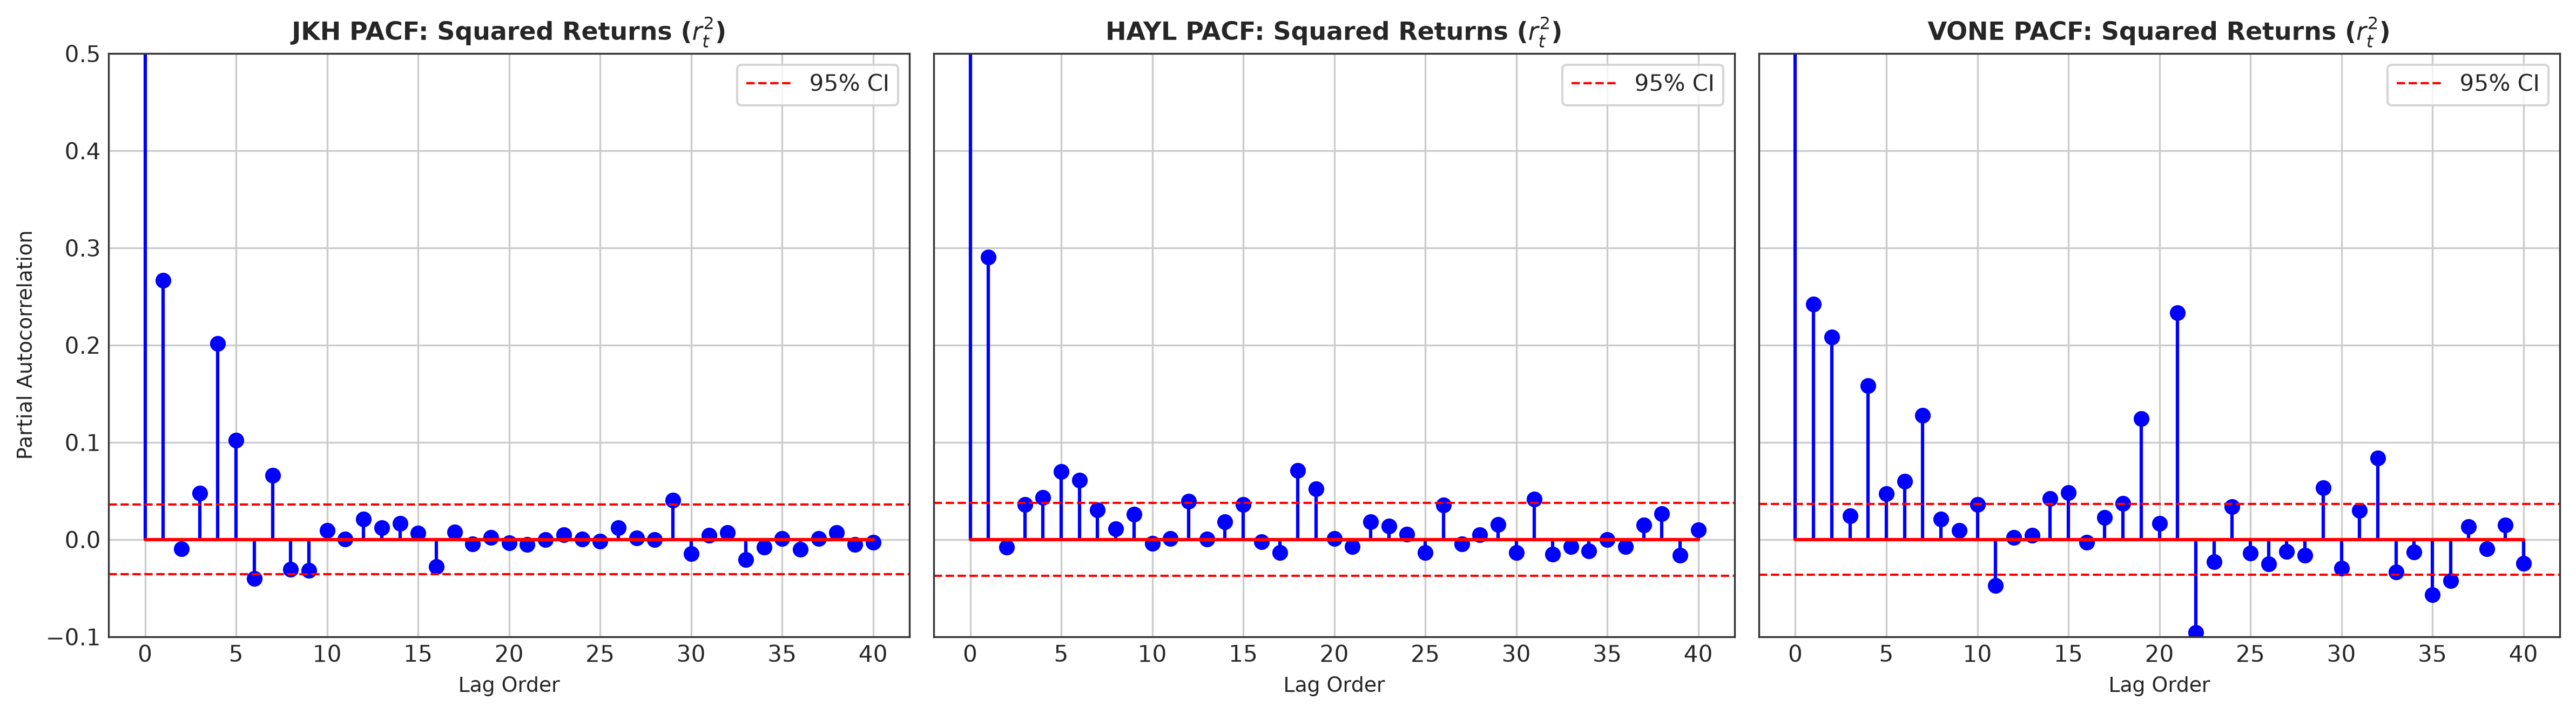

In [ ]:
max_lags = 40

# 1. ACF of Daily Log Returns
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=300, sharey=True)
for i, eq in enumerate(equities):
    r = dfs[eq]['Log_Return_Calc'].dropna().values
    acf_vals = acf(r, nlags=max_lags, fft=True)
    lags = np.arange(len(acf_vals))
    
    axes[i].stem(lags, acf_vals, linefmt='b-', markerfmt='bo', basefmt='r-')
    ci = 1.96 / np.sqrt(len(r))
    axes[i].axhline(ci, color='red', linestyle='--', lw=1, label='95% CI')
    axes[i].axhline(-ci, color='red', linestyle='--', lw=1)
    axes[i].set_title(f'{eq} ACF: Daily Log Returns', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Lag Order', fontsize=9)
    if i == 0:
        axes[i].set_ylabel('Autocorrelation', fontsize=9)
    axes[i].set_ylim(-0.25, 0.25)
    axes[i].legend(loc='upper right', frameon=True)

plt.tight_layout()
fig.savefig(os.path.join(figures_base, 'acf_returns.png'))
plt.show()

# 2. PACF of Daily Log Returns
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=300, sharey=True)
for i, eq in enumerate(equities):
    r = dfs[eq]['Log_Return_Calc'].dropna().values
    pacf_vals = pacf(r, nlags=max_lags, method='ywm')
    lags = np.arange(len(pacf_vals))
    
    axes[i].stem(lags, pacf_vals, linefmt='b-', markerfmt='bo', basefmt='r-')
    ci = 1.96 / np.sqrt(len(r))
    axes[i].axhline(ci, color='red', linestyle='--', lw=1, label='95% CI')
    axes[i].axhline(-ci, color='red', linestyle='--', lw=1)
    axes[i].set_title(f'{eq} PACF: Daily Log Returns', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Lag Order', fontsize=9)
    if i == 0:
        axes[i].set_ylabel('Partial Autocorrelation', fontsize=9)
    axes[i].set_ylim(-0.25, 0.25)
    axes[i].legend(loc='upper right', frameon=True)

plt.tight_layout()
fig.savefig(os.path.join(figures_base, 'pacf_returns.png'))
plt.show()

# 3. ACF of Squared Returns (r_t^2)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=300, sharey=True)
for i, eq in enumerate(equities):
    r = dfs[eq]['Log_Return_Calc'].dropna().values
    r2 = (r - np.mean(r))**2
    acf_vals = acf(r2, nlags=max_lags, fft=True)
    lags = np.arange(len(acf_vals))
    
    axes[i].stem(lags, acf_vals, linefmt='b-', markerfmt='bo', basefmt='r-')
    ci = 1.96 / np.sqrt(len(r))
    axes[i].axhline(ci, color='red', linestyle='--', lw=1, label='95% CI')
    axes[i].axhline(-ci, color='red', linestyle='--', lw=1)
    axes[i].set_title(f'{eq} ACF: Squared Returns ($r_t^2$)', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Lag Order', fontsize=9)
    if i == 0:
        axes[i].set_ylabel('Autocorrelation', fontsize=9)
    axes[i].set_ylim(-0.05, 0.5)
    axes[i].legend(loc='upper right', frameon=True)

plt.tight_layout()
fig.savefig(os.path.join(figures_base, 'acf_squared_returns.png'))
plt.show()

# 4. PACF of Squared Returns (r_t^2)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=300, sharey=True)
for i, eq in enumerate(equities):
    r = dfs[eq]['Log_Return_Calc'].dropna().values
    r2 = (r - np.mean(r))**2
    pacf_vals = pacf(r2, nlags=max_lags, method='ywm')
    lags = np.arange(len(pacf_vals))
    
    axes[i].stem(lags, pacf_vals, linefmt='b-', markerfmt='bo', basefmt='r-')
    ci = 1.96 / np.sqrt(len(r))
    axes[i].axhline(ci, color='red', linestyle='--', lw=1, label='95% CI')
    axes[i].axhline(-ci, color='red', linestyle='--', lw=1)
    axes[i].set_title(f'{eq} PACF: Squared Returns ($r_t^2$)', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Lag Order', fontsize=9)
    if i == 0:
        axes[i].set_ylabel('Partial Autocorrelation', fontsize=9)
    axes[i].set_ylim(-0.1, 0.5)
    axes[i].legend(loc='upper right', frameon=True)

plt.tight_layout()
fig.savefig(os.path.join(figures_base, 'pacf_squared_returns.png'))
plt.show()
